   user_id   event_type           timestamp  time_on_page_sec
0      101    page_view 2024-02-01 10:00:00                45
1      102        click 2024-02-01 10:02:00                12
2      103  add_to_cart 2024-02-01 10:05:00                30
3      104    page_view 2024-02-01 10:10:00               120
4      105     purchase 2024-02-01 10:15:00                 5
     type          query user_id session_id
0  search  running shoes     101         s1
         total_events  total_time
user_id                          
101                 2          53
102                 1          12
103                 1          30
104                 1         120
105                 1           5
106                 1         200


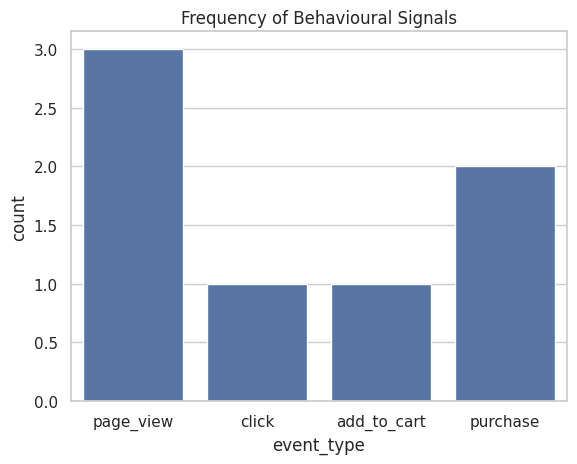

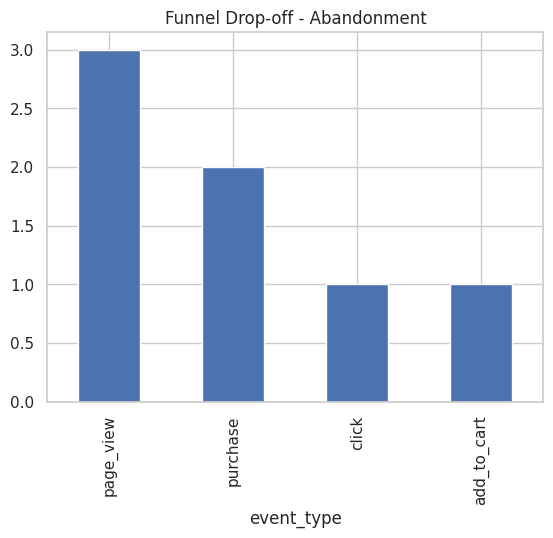

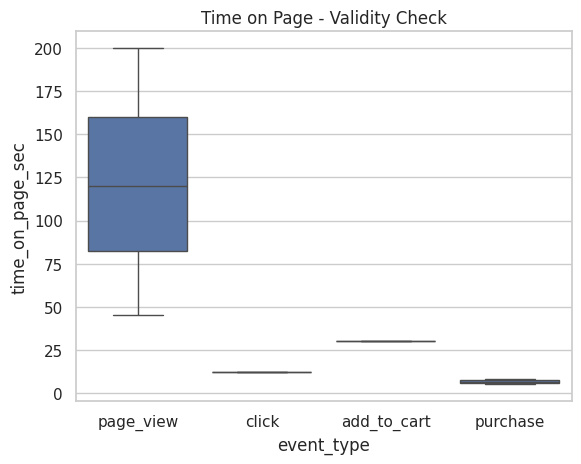

In [1]:
# BEHAVIOURAL DATA USER GUIDE
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')

# STRUCTURED DATA
structured_data = {
    'user_id': [101, 102, 103, 104, 105, 101, 106],
    'event_type': ['page_view', 'click', 'add_to_cart', 'page_view', 'purchase', 'purchase', 'page_view'],
    'timestamp': pd.to_datetime(['2024-02-01 10:00', '2024-02-01 10:02', '2024-02-01 10:05', '2024-02-01 10:10', '2024-02-01 10:15', '2024-02-01 11:00', '2024-02-01 11:05']),
    'time_on_page_sec': [45, 12, 30, 120, 5, 8, 200]
}
df_structured = pd.DataFrame(structured_data)
print(df_structured.head())

# SEMI-STRUCTURED DATA
json_logs = '[{"user_id": 101, "session_id": "s1", "events": [{"type": "search", "query": "running shoes"}]}]'
semi_data = json.loads(json_logs)
df_semi = pd.json_normalize(semi_data, 'events', ['user_id', 'session_id'])
print(df_semi)

# STRUCTURING
user_summary = df_structured.groupby('user_id').agg(total_events=('event_type','count'), total_time=('time_on_page_sec','sum'))
print(user_summary)

# EDA - CHARTS
sns.countplot(data=df_structured, x='event_type')
plt.title('Frequency of Behavioural Signals')
plt.show()

df_structured['event_type'].value_counts().plot(kind='bar')
plt.title('Funnel Drop-off - Abandonment')
plt.show()

sns.boxplot(data=df_structured, x='event_type', y='time_on_page_sec')
plt.title('Time on Page - Validity Check')
plt.show()